# Preparation of the dataset

> Dataset information

I think it is used to classify types of cactus

In [7]:
import zipfile
file_name = "aerial-cactus-identification.zip"
zip_file_handle = zipfile.ZipFile(file_name)
zip_file_handle.extractall()

In [ ]:
import torch
from torch import nn

In [ ]:
torch.cuda

<module 'torch.cuda' from '/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py'>

In [ ]:
torch.cuda.is_available()

True

In [6]:
device = "cuda"

In [ ]:
tensor = torch.tensor(1).to(device)

In [ ]:
tensor

tensor(1, device='cuda:0')

In [ ]:
torch.cuda.is_available()

True

# Training

In [10]:
import numpy as np
import pandas as pd
from torch import nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
%matplotlib inline

In [14]:
train_zip = zipfile.ZipFile("train.zip")
train_zip.extractall("train_images")
test_zip = zipfile.ZipFile("test.zip")
test_zip.extractall()

In [15]:
from pathlib import Path

TRAIN_ZIP_BASE = Path("train_images/train")
TRAIN_LABELS = Path("train.csv")
TEST_BASE = Path("test")

In [16]:
labels = pd.read_csv("train.csv")
submission=pd.read_csv("sample_submission.csv")

In [17]:
labels.head()

,id,has_cactus
0,0004be2cfeaba1c0361d39e2b000257b.jpg,1
1,000c8a36845c0208e833c79c1bffedd1.jpg,1
2,000d1e9a533f62e55c289303b072733d.jpg,1
3,0011485b40695e9138e92d0b3fb55128.jpg,1
4,0014d7a11e90b62848904c1418fc8cf2.jpg,1


In [18]:
labels.tail()

,id,has_cactus
17495,ffede47a74e47a5930f81c0b6896479e.jpg,0
17496,ffef6382a50d23251d4bc05519c91037.jpg,1
17497,fff059ecc91b30be5745e8b81111dc7b.jpg,1
17498,fff43acb3b7a23edcc4ae937be2b7522.jpg,0
17499,fffd9e9b990eba07c836745d8aef1a3a.jpg,1


In [20]:
labels['has_cactus'].value_counts()

,count
has_cactus,
1,13136
0,4364


<Axes: >

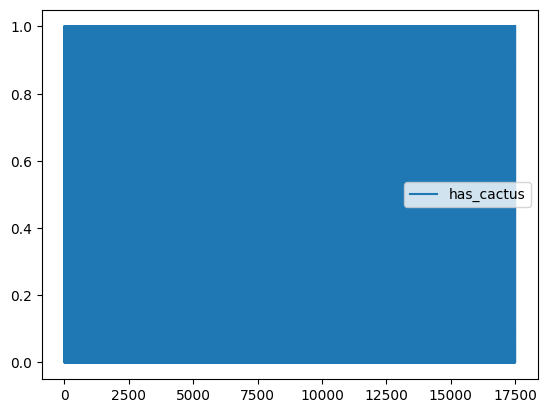

In [21]:
labels.plot()

([<matplotlib.patches.Wedge at 0x7fdb2065dde0>,
 [Text(-0.7762799652368623, 0.7793519202336362, 'Has cactus'),
  Text(0.7762800017209578, -0.7793518838933475, "Doesn't have cactus")],
 [Text(-0.423425435583743, 0.42510104740016513, '24.9%'),
  Text(0.4234254554841587, -0.4251010275781895, '75.1%')])

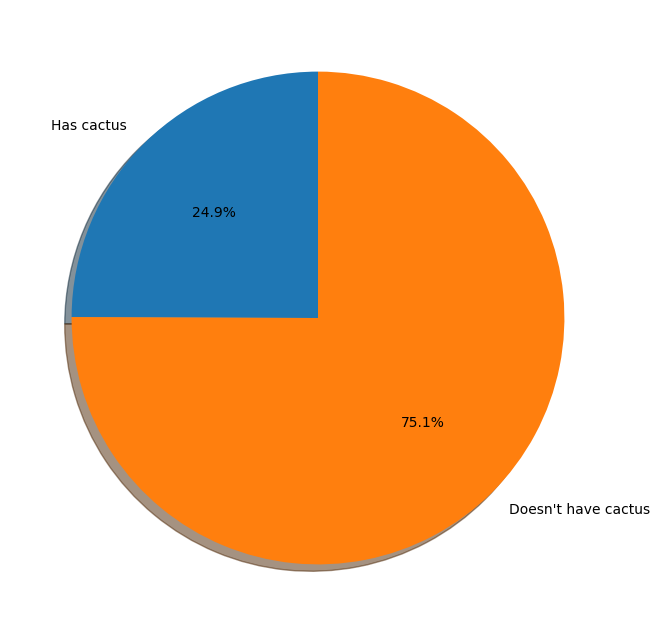

In [24]:
label = "Has cactus", "Doesn't have cactus"
plt.figure(figsize=(8,8))
plt.pie(labels.groupby('has_cactus').size(), labels=label, autopct="%1.1f%%",
        shadow=True,startangle=90)

In [26]:
import torch
torch.tensor(1).to("cuda")

tensor(1, device='cuda:0')

In [27]:
device = "cuda"

In [32]:
t = torch.randn(10).to(device)

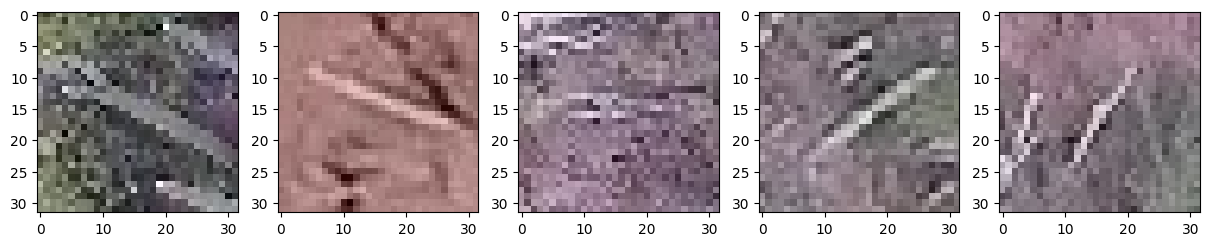

In [34]:
import matplotlib.image as img
import os
fig, ax = plt.subplots(1,5, figsize=(15,3))

for i, idx in enumerate(labels[labels['has_cactus']==1]['id'][-5:]):
  path = os.path.join(TRAIN_ZIP_BASE, idx)
  ax[i].imshow(img.imread(path))

In [39]:
labels[labels['has_cactus']==1]['id'][0]

'0004be2cfeaba1c0361d39e2b000257b.jpg'

TypeError: Image data of dtype object cannot be converted to float

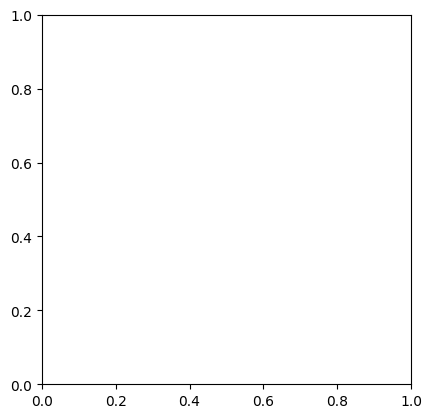

In [41]:
plt.imshow(TRAIN_ZIP_BASE / labels[labels['has_cactus']==1]['id'][0])

In [43]:
labels[labels['has_cactus']==1].shape

(13136, 2)

In [44]:
import numpy as np
def imshow(image, ax=None, title=None, normalize=True):
  if ax is None:
    fig, ax = plt.subplots()
  image = image.numpy().transpose((1,2,0))
  if normalize:
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229,0.224,0.225])
    image= std* image + mean
    image = np.clip(image, 0,1)
  ax.imshow(image)
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.tick_params(axis='both', length=0)
  ax.set_xticklabels('')
  ax.set_yticklabels('')
  return ax

In [45]:
class CactiDS(Dataset):
  def __init__(self):
    return len(self.data)
  def __getitem__(self, index):
    img_name, label = self.data[index]
    img_path = os.path.join(self.path, img_name)
    image = img.imread(img_path)
    if self.transform is not None:
      image = self.transform(image)
    return image, label

In [46]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229,0.224,0.225])
train_transform= transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
test_transform= transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
valid_transform= transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [47]:
train_data, test_data = train_test_split(labels, stratify=labels.has_cactus,
                                         test_size=0.2)

In [48]:
num_epochs = 35
num_classes = 2
batch_size = 25
learning_rate = 0.001

In [51]:
train_loader = DataLoader(dataset = train_data, batch_size = batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(dataset = test_data, batch_size = batch_size, shuffle=False, num_workers=0)